# <center>🛠️ Практика 2. Работа с данными: очистка, пропуски, выбросы, преобразования</center>
### <center>Прикладные технологии ИИ · 90 минут · Модуль 1</center>

<div style='text-align: center; margin: 20px;'>
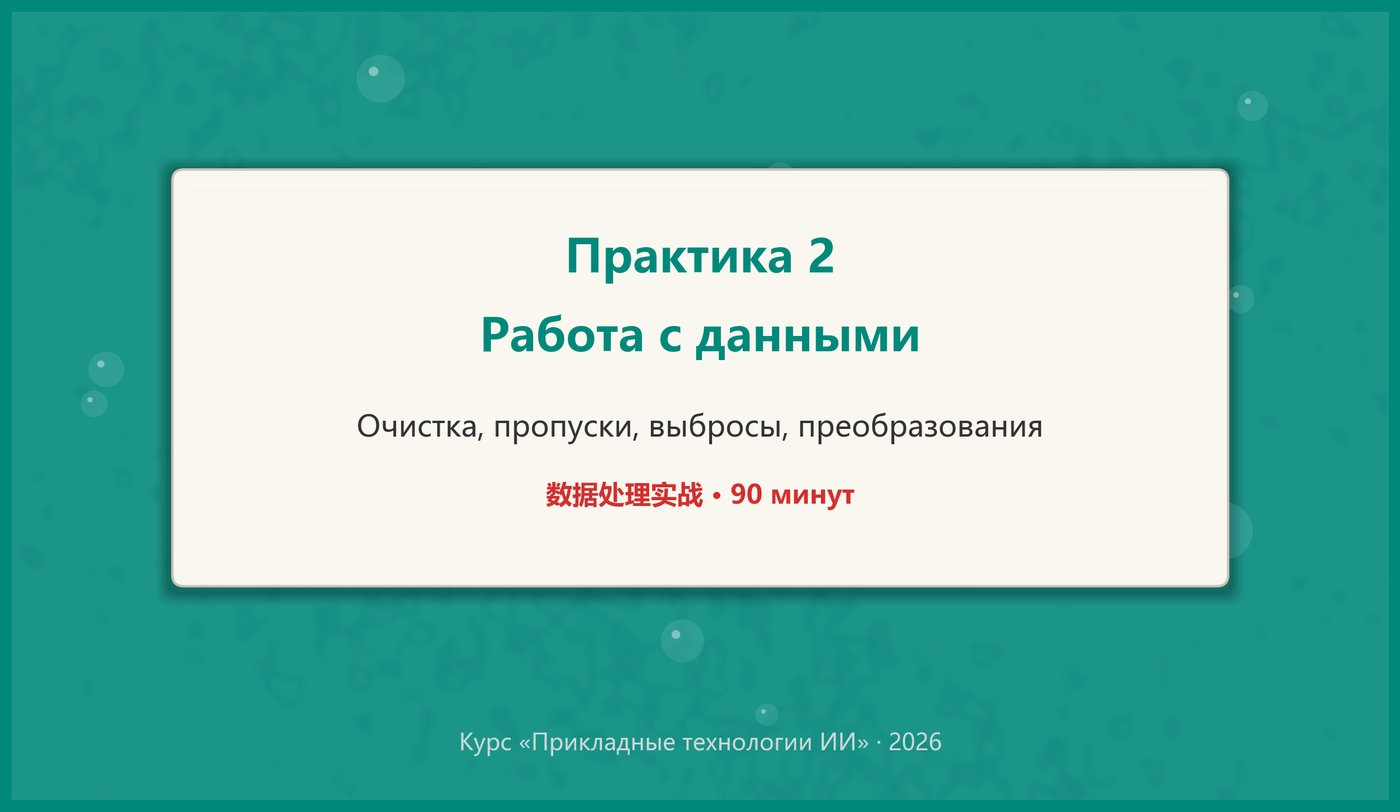
</div>

<div style='background-color: #E0F2F1; padding: 15px; border-left: 5px solid #00897B; margin: 20px 0;'>
<b>🎯 Цель практики:</b><br>
Научиться обрабатывать «грязные» данные: находить пропуски, выбросы, дубликаты, преобразовывать типы и создавать новые признаки.<br><br>
<b>⏱️ План (90 минут):</b><br>
• 10 мин — NumPy и основы Pandas<br>
• 20 мин — пропуски и способы их заполнения<br>
• 15 мин — дубликаты и выбросы<br>
• 15 мин — преобразования типов и значений<br>
• 15 мин — группировка и агрегация<br>
• 10 мин — самостоятельные задания<br>
• 5 мин — выводы
</div>

<div style='background-color: #FFF3E0; padding: 10px; border-left: 5px solid #F57C00; margin: 20px 0;'>
<b>💡 Главное правило:</b> «Мусор на входе — мусор на выходе» (Garbage In, Garbage Out). Качество модели напрямую зависит от качества данных.
</div>

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата: _______________</i></center>
<center><i>Студент: _______________</i></center>

---
## 📖 Краткое содержание практики

В этой практике мы пройдём **полный цикл очистки данных** — от «грязной» таблицы до чистого набора, готового для обучения модели. Это самый важный навык в реальной работе: по статистике, специалист по данным тратит **60–80% рабочего времени** именно на очистку и подготовку данных.

### Какие темы мы затронем

1. **NumPy** — фундамент для всех вычислений: массивы, векторизация, broadcasting.
2. **Pandas DataFrame** — основной инструмент для табличных данных.
3. **Очистка данных** — поиск дубликатов, обработка пропусков, выявление выбросов.
4. **Преобразование признаков** — кодирование категорий, масштабирование, новые вычисляемые столбцы.
5. **Группировка и агрегация** — сводные таблицы, средние по группам.

### Реалистичный сценарий

Все данные в этой практике — синтетические, но намеренно «испорченные»: есть пропуски, дубликаты, выбросы и строковые значения там, где должны быть числа. Именно так выглядят данные в реальных компаниях: опечатки операторов, обрывы связи при сборе, разные единицы измерения, — всё это приходится чинить вручную.

<div style='background-color: #FFF3E0; padding: 15px; border-left: 5px solid #E65100; margin: 20px 0;'>
<b>🎯 К концу практики вы должны уметь:</b><br>
• Создавать DataFrame из словаря и читать его из CSV;<br>
• Находить и удалять дубликаты, пропуски и выбросы;<br>
• Применять <code>map</code>, <code>apply</code>, <code>replace</code> для преобразования столбцов;<br>
• Делать группировку <code>groupby</code> и визуализировать результаты.
</div>


---
## 🔧 Настройка шрифтов

Выполните эту ячейку первой, чтобы иероглифы в графиках не превращались в квадраты:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('✅ Библиотеки импортированы, шрифты настроены')

✅ Библиотеки импортированы, шрифты настроены


---
## 🔢 NumPy — что такое массив (array)

NumPy — это библиотека для работы с **многомерными массивами**. Массив NumPy (`np.ndarray`) — это «таблица чисел» в памяти: одномерная (вектор), двумерная (матрица) или n-мерная. В отличие от списков Python, все элементы массива обязаны иметь один тип (обычно `float64` или `int64`), и благодаря этому операции с массивами работают в **10–100 раз быстрее**, чем циклы `for` по обычным спискам.

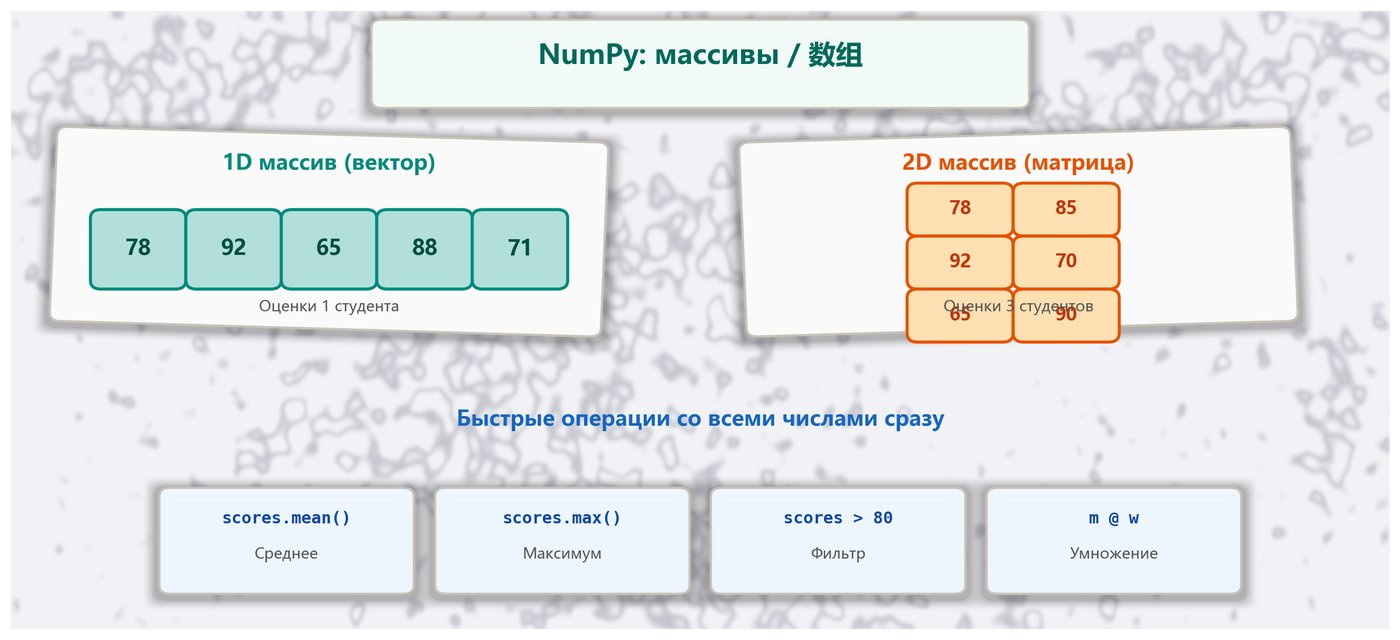

**Почему массив важен для ИИ:** любая картинка — это трёхмерный массив (высота × ширина × каналы RGB), любой звук — одномерный массив амплитуд, любая таблица данных — двумерный массив признаков. Все библиотеки машинного обучения (scikit-learn, PyTorch, TensorFlow) под капотом работают именно с массивами NumPy.

**Практический совет:** если вы видите, что ваш код на Python работает с числами медленно — перепишите его на NumPy-операции. Это называется *векторизацией* и обычно даёт ускорение в десятки раз.


---
# 📊 ЧАСТЬ 1. Пайплайн очистки данных

Любая работа с данными начинается с **осмотра** и заканчивается **чистым** набором, готовым для модели.

<div style='text-align: center; margin: 20px;'>
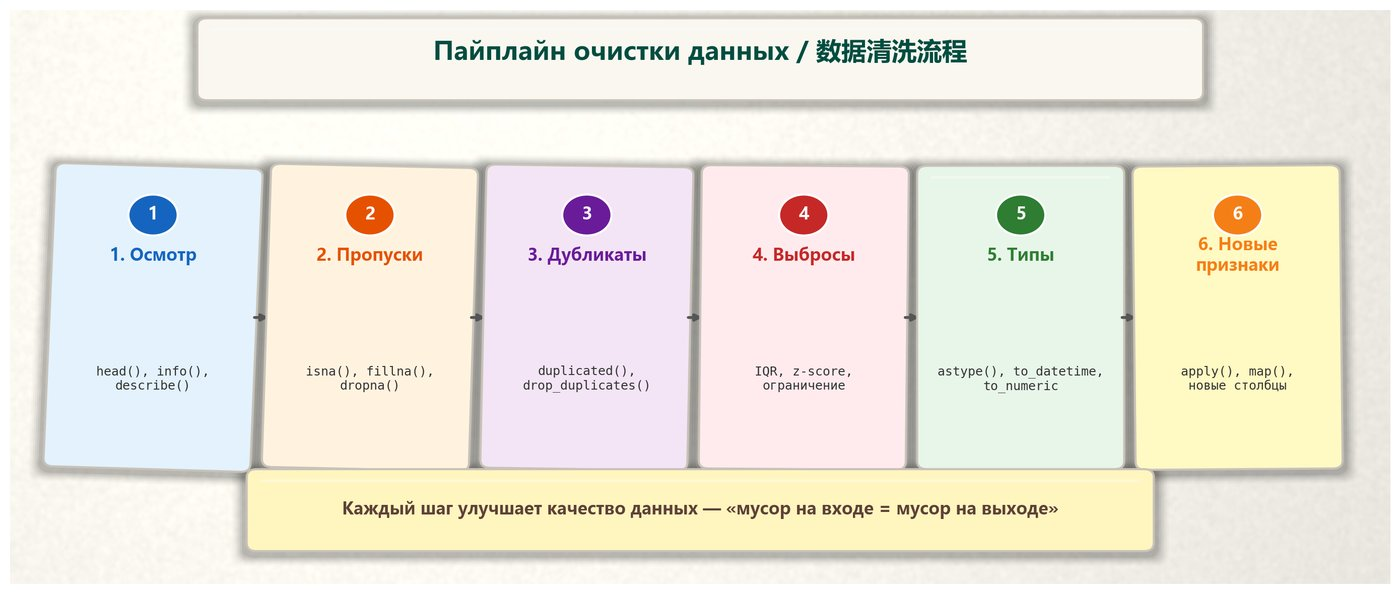
</div>

Пройдём по каждому шагу на реалистичном примере.

---
# 📋 ЧАСТЬ 2. Создаём «грязные» данные

Чтобы научиться чистить, нужны грязные данные. Создадим таблицу студентов с типичными проблемами:

In [2]:
# Создаём «грязную» таблицу — типичные проблемы реальных данных
df = pd.DataFrame({
    'name': ['Li', 'Wang', 'Zhang', 'Liu', 'Chen', 'Zhao', 'Li', 'Sun', 'Zhou', 'Wu'],
    'group': ['A', 'A', 'B', 'B', 'A', 'B', 'A', 'C', 'B', 'A'],
    'age': [20, 21, 19, 22, 20, 21, 20, 150, 22, 20],  # 150 — явная ошибка!
    'math': [78, 92, None, 88, 71, 95, 78, 60, None, 85],  # пропуски
    'python': [85, 70, 90, None, 66, 80, 85, 55, 75, 88],  # пропуск
    'score': ['81', '81.5', '85', '77', '68', '88', '81', '57', '78', '86'],  # строки вместо чисел!
    'date': ['2025-09-01', '2025-09-01', '2025-09-02', '2025-09-02', 
             '2025-09-03', '2025-09-03', '2025-09-01', '2025-09-04', 
             '2025-09-02', '2025-09-03']
})

print('Исходная «грязная» таблица:')
display(df)

Исходная «грязная» таблица:


,name,group,age,math,python,score,date
0,Li,A,20,78.0,85.0,81,2025-09-01
1,Wang,A,21,92.0,70.0,81.5,2025-09-01
2,Zhang,B,19,NaN,90.0,85,2025-09-02
3,Liu,B,22,88.0,NaN,77,2025-09-02
4,Chen,A,20,71.0,66.0,68,2025-09-03
5,Zhao,B,21,95.0,80.0,88,2025-09-03
6,Li,A,20,78.0,85.0,81,2025-09-01
7,Sun,C,150,60.0,55.0,57,2025-09-04
8,Zhou,B,22,NaN,75.0,78,2025-09-02
9,Wu,A,20,85.0,88.0,86,2025-09-03


---
## 📊 Pandas DataFrame — структура данных для таблиц

**DataFrame** — это главная структура данных в Pandas. Его можно представить как таблицу Excel внутри Python: есть строки (с индексами), есть именованные столбцы, и каждый столбец может иметь свой тип данных.

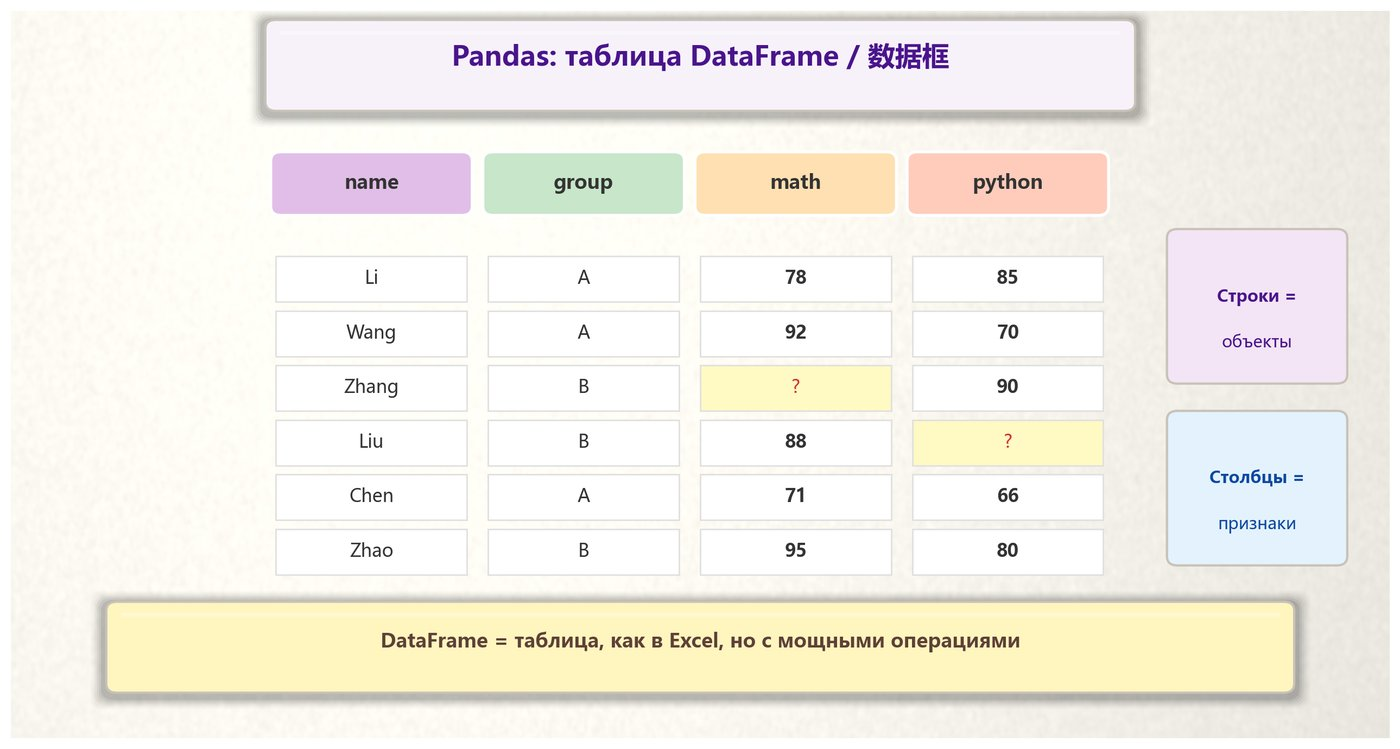

### Анатомия DataFrame

| Часть | Что это | Как получить |
|---|---|---|
| **Индекс (index)** | Метки строк (0, 1, 2, …) | `df.index` |
| **Столбцы (columns)** | Имена столбцов | `df.columns` |
| **Значения (values)** | Массив NumPy под капотом | `df.values` |
| **dtypes** | Типы данных каждого столбца | `df.dtypes` |

**Главное правило:** DataFrame — это *не* таблица базы данных и *не* Excel-лист. Это объект с богатым API: фильтрация, группировка, объединение, временные ряды, — всё это делается методами `df.loc[]`, `df.groupby()`, `df.merge()`, `df.resample()` и сотнями других. В этой практике мы пройдём основные из них.


### Что здесь не так? (Найдите все проблемы!)

1. **Дубликат:** Li встречается дважды (строки 0 и 6)
2. **Выброс:** возраст 150 — явно ошибка ввода
3. **Пропуски:** в `math` и `python` есть `None`
4. **Неверный тип:** `score` — строки, хотя должны быть числа
5. **Дата как строка:** `date` — текст, а не дата
6. **Невозможная группа:** `C` — такой группы нет

---
# 🔍 Шаг 1. Осмотр данных

Перед любой обработкой — **посмотрим**, что у нас есть:

In [3]:
print('=== Размер таблицы ===')
print(f'Строк: {df.shape[0]}, столбцов: {df.shape[1]}')
print()

print('=== Типы данных ===')
print(df.dtypes)
print()

print('=== Пропуски в каждом столбце ===')
print(df.isna().sum())
print()

print('=== Числовая статистика ===')
print(df.describe())

=== Размер таблицы ===
Строк: 10, столбцов: 7

=== Типы данных ===
name       object
group      object
age         int64
math      float64
python    float64
score      object
date       object
dtype: object

=== Пропуски в каждом столбце ===
name      0
group     0
age       0
math      2
python    1
score     0
date      0
dtype: int64

=== Числовая статистика ===
              age       math     python
count   10.000000   8.000000   9.000000
mean    33.500000  80.875000  77.111111
std     40.945085  11.593563  11.645218
min     19.000000  60.000000  55.000000
25%     20.000000  76.250000  70.000000
50%     20.500000  81.500000  80.000000
75%     21.750000  89.000000  85.000000
max    150.000000  95.000000  90.000000


### Что видим?

- `df.shape` — 10 строк × 8 столбцов
- `df.dtypes` — `score` имеет тип `object` (строки!), хотя должен быть числом
- `df.isna().sum()` — есть пропуски в `math` и `python`
- `df.describe()` — максимальный возраст 150! Это выброс.

<div style='background-color: #E1F5FE; padding: 15px; border-left: 5px solid #0288D1; margin: 20px 0;'>
<b>💡 Правило:</b> Всегда начинайте с <code>df.info()</code>, <code>df.describe()</code> и <code>df.head()</code>. Это экономит часы работы.
</div>

---
# 🧹 Шаг 2. Работа с дубликатами

Дубликаты — это строки, которые полностью или частично повторяются. Они искажают статистику.

In [4]:
# Находим полные дубликаты
print('Полные дубликаты:')
print(df.duplicated())
print()

# Дубликаты по определённым столбцам (например, по имени)
print('Дубликаты по имени:')
print(df.duplicated(subset=['name']))
print()

print('Повторяющиеся имена:')
print(df[df.duplicated(subset=['name'], keep=False)])

Полные дубликаты:
0    False
1    False
2    False
3    False
4    False
5    False
6     True
7    False
8    False
9    False
dtype: bool

Дубликаты по имени:
0    False
1    False
2    False
3    False
4    False
5    False
6     True
7    False
8    False
9    False
dtype: bool

Повторяющиеся имена:
  name group  age  math  python score        date
0   Li     A   20  78.0    85.0    81  2025-09-01
6   Li     A   20  78.0    85.0    81  2025-09-01


In [5]:
# Удаляем дубликаты (оставляем первую встречу)
df = df.drop_duplicates(subset=['name'], keep='first').reset_index(drop=True)
print(f'После удаления дубликатов: {df.shape[0]} строк')
display(df)

После удаления дубликатов: 9 строк


,name,group,age,math,python,score,date
0,Li,A,20,78.0,85.0,81,2025-09-01
1,Wang,A,21,92.0,70.0,81.5,2025-09-01
2,Zhang,B,19,NaN,90.0,85,2025-09-02
3,Liu,B,22,88.0,NaN,77,2025-09-02
4,Chen,A,20,71.0,66.0,68,2025-09-03
5,Zhao,B,21,95.0,80.0,88,2025-09-03
6,Sun,C,150,60.0,55.0,57,2025-09-04
7,Zhou,B,22,NaN,75.0,78,2025-09-02
8,Wu,A,20,85.0,88.0,86,2025-09-03


### Что произошло?

- `drop_duplicates(subset=['name'])` — удаляет строки с повторяющимися именами
- `keep='first'` — оставляет первую встречу, остальные удаляет
- `reset_index(drop=True)` — перенумеровывает индексы

🔍 **Вопрос:** сколько строк было до и после? Почему?

---
# 🎯 Шаг 3. Работа с выбросами

**Выброс (异常值)** — это значение, которое сильно отличается от остальных. Например, возраст 150 лет.

<div style='text-align: center; margin: 20px;'>
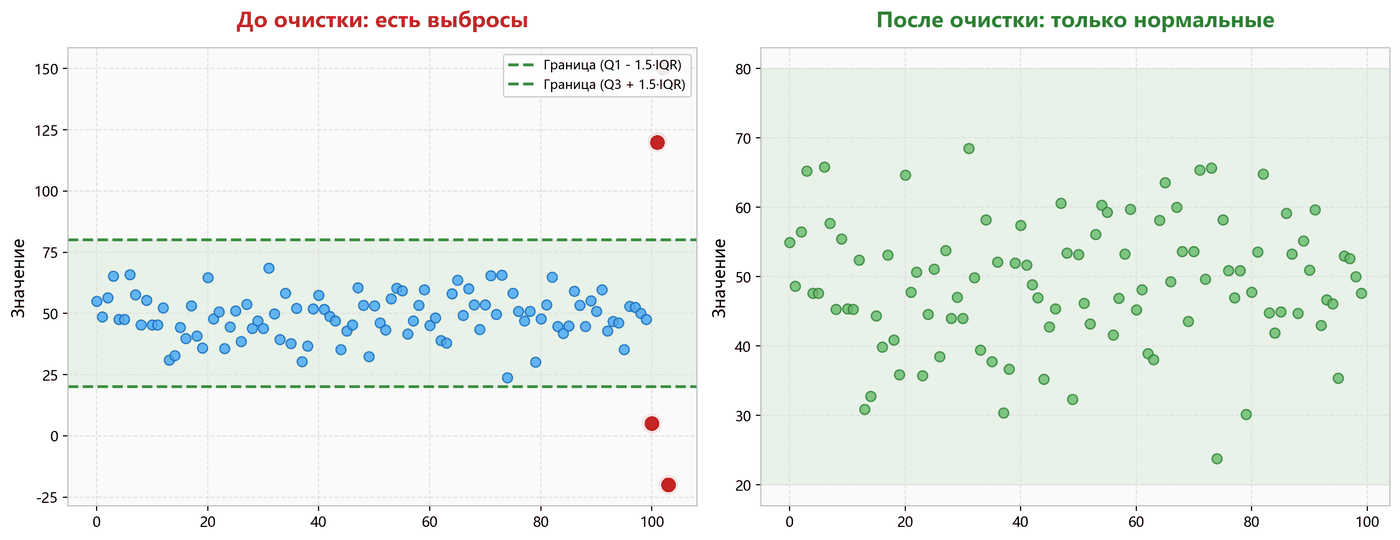
</div>

### Как найти выбросы? Метод IQR

**IQR (межквартильный размах)** = Q3 − Q1
- Q1 (25%) — нижняя граница
- Q3 (75%) — верхняя граница
- Границы: `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`
- Всё, что вне границ — выброс

In [6]:
# Находим выбросы в столбце age методом IQR
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print(f'Q1 = {Q1}, Q3 = {Q3}, IQR = {IQR}')
print(f'Границы: [{lower:.1f}, {upper:.1f}]')
print()

outliers = df[(df['age'] < lower) | (df['age'] > upper)]
print('Выбросы:')
display(outliers)

Q1 = 20.0, Q3 = 22.0, IQR = 2.0
Границы: [17.0, 25.0]

Выбросы:


,name,group,age,math,python,score,date
6,Sun,C,150,60.0,55.0,57,2025-09-04


In [7]:
# Вариант 1: удалить строки с выбросами
df_clean = df[(df['age'] >= lower) & (df['age'] <= upper)].copy()
print(f'После удаления выбросов: {df_clean.shape[0]} строк')
display(df_clean)

После удаления выбросов: 8 строк


,name,group,age,math,python,score,date
0,Li,A,20,78.0,85.0,81,2025-09-01
1,Wang,A,21,92.0,70.0,81.5,2025-09-01
2,Zhang,B,19,NaN,90.0,85,2025-09-02
3,Liu,B,22,88.0,NaN,77,2025-09-02
4,Chen,A,20,71.0,66.0,68,2025-09-03
5,Zhao,B,21,95.0,80.0,88,2025-09-03
7,Zhou,B,22,NaN,75.0,78,2025-09-02
8,Wu,A,20,85.0,88.0,86,2025-09-03


In [8]:
# Вариант 2: ограничить выбросы (winsorization)
df_wins = df.copy()
df_wins['age'] = df_wins['age'].clip(lower, upper)
print('После ограничения выбросов:')
display(df_wins[['name', 'age']])

После ограничения выбросов:


,name,age
0,Li,20
1,Wang,21
2,Zhang,19
3,Liu,22
4,Chen,20
5,Zhao,21
6,Sun,25
7,Zhou,22
8,Wu,20


### Какой вариант выбрать?

| Способ | Когда использовать |
|--------|-------------------|
| **Удалить** | Выброс — явная ошибка (возраст 150) |
| **Ограничить** | Выброс возможен, но нужно сохранить строку |
| **Заменить средним/медианой** | Как с пропусками |
| **Оставить** | Если выброс — реальное, но редкое значение |

В нашем случае возраст 150 — явная ошибка, поэтому **удаляем**.

---
# ❓ Шаг 4. Работа с пропусками

Пропуски (缺失值) — одна из самых частых проблем. В Pandas они обозначаются как `NaN` (Not a Number).

<div style='text-align: center; margin: 20px;'>
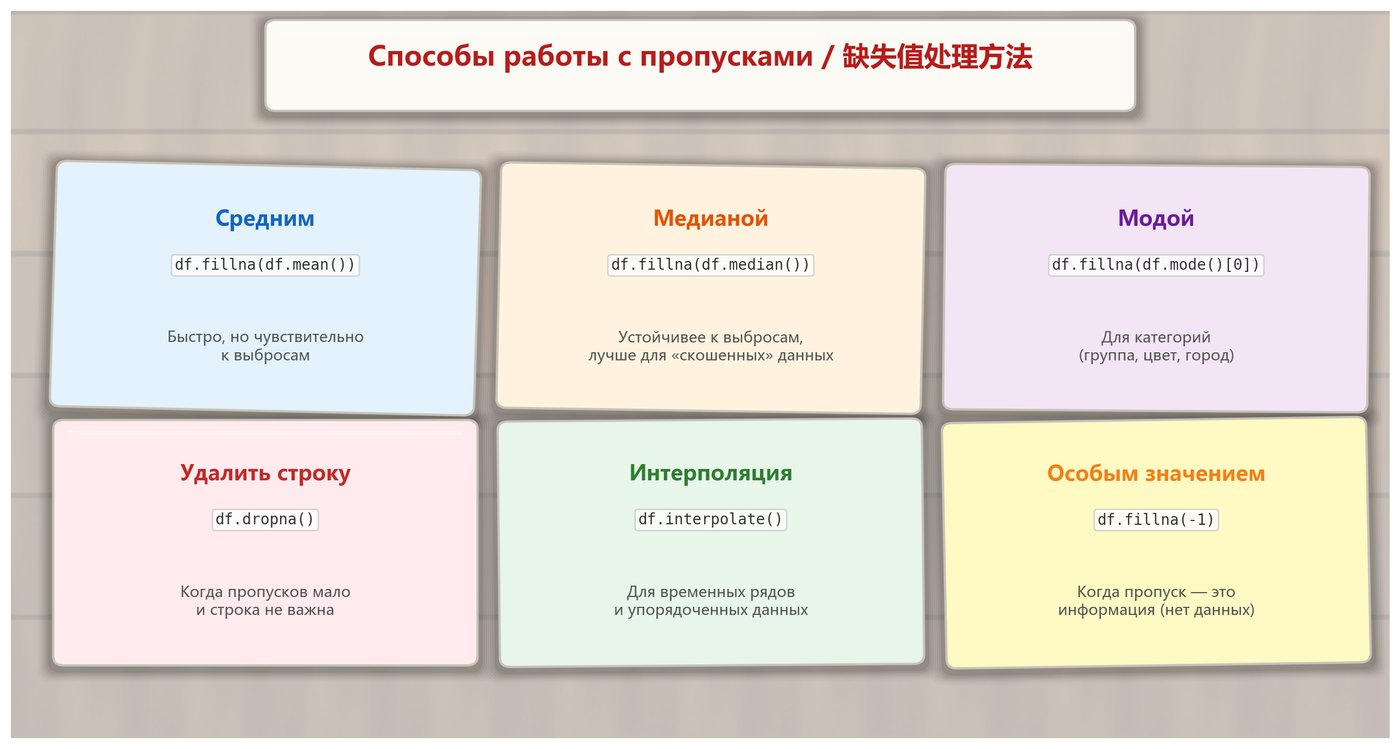
</div>

In [9]:
# Продолжаем с df_clean (без выбросов)
print('Пропуски ДО обработки:')
print(df_clean.isna().sum())
print()

# Вариант 1: заполнить средним
df_clean['math'] = df_clean['math'].fillna(df_clean['math'].mean())

# Вариант 2: заполнить медианой (устойчивее к выбросам)
df_clean['python'] = df_clean['python'].fillna(df_clean['python'].median())

print('Пропуски ПОСЛЕ обработки:')
print(df_clean.isna().sum())
print()

display(df_clean)

Пропуски ДО обработки:
name      0
group     0
age       0
math      2
python    1
score     0
date      0
dtype: int64

Пропуски ПОСЛЕ обработки:
name      0
group     0
age       0
math      0
python    0
score     0
date      0
dtype: int64



,name,group,age,math,python,score,date
0,Li,A,20,78.000000,85.0,81,2025-09-01
1,Wang,A,21,92.000000,70.0,81.5,2025-09-01
2,Zhang,B,19,84.833333,90.0,85,2025-09-02
3,Liu,B,22,88.000000,80.0,77,2025-09-02
4,Chen,A,20,71.000000,66.0,68,2025-09-03
5,Zhao,B,21,95.000000,80.0,88,2025-09-03
7,Zhou,B,22,84.833333,75.0,78,2025-09-02
8,Wu,A,20,85.000000,88.0,86,2025-09-03


### Сравним способы заполнения

| Способ | Код | Когда использовать |
|--------|-----|-------------------|
| Средним | `fillna(df.mean())` | Данные распределены нормально |
| Медианой | `fillna(df.median())` | Есть выбросы или «скошенное» распределение |
| Модой | `fillna(df.mode()[0])` | Для категориальных данных (группа, цвет) |
| Удалить строку | `dropna()` | Пропусков мало, строка не важна |
| Удалить столбец | `dropna(axis=1)` | В столбце больше 50% пропусков |
| Интерполяция | `interpolate()` | Для временных рядов |
| Особым значением | `fillna(-1)` | Когда пропуск — это информация |

---
# 🔄 Шаг 5. Преобразование типов

Часто данные приходят в неправильном типе. Например, число записано как строка.

In [10]:
print('Типы ДО преобразования:')
print(df_clean.dtypes)
print()

# Преобразуем score из строки в число
df_clean['score'] = pd.to_numeric(df_clean['score'], errors='coerce')

# Преобразуем date в настоящий тип datetime
df_clean['date'] = pd.to_datetime(df_clean['date'])

# Возраст — в целый тип
df_clean['age'] = df_clean['age'].astype(int)

print('Типы ПОСЛЕ преобразования:')
print(df_clean.dtypes)
print()

display(df_clean)

Типы ДО преобразования:
name       object
group      object
age         int64
math      float64
python    float64
score      object
date       object
dtype: object

Типы ПОСЛЕ преобразования:
name              object
group             object
age                int64
math             float64
python           float64
score            float64
date      datetime64[ns]
dtype: object



,name,group,age,math,python,score,date
0,Li,A,20,78.000000,85.0,81.0,2025-09-01
1,Wang,A,21,92.000000,70.0,81.5,2025-09-01
2,Zhang,B,19,84.833333,90.0,85.0,2025-09-02
3,Liu,B,22,88.000000,80.0,77.0,2025-09-02
4,Chen,A,20,71.000000,66.0,68.0,2025-09-03
5,Zhao,B,21,95.000000,80.0,88.0,2025-09-03
7,Zhou,B,22,84.833333,75.0,78.0,2025-09-02
8,Wu,A,20,85.000000,88.0,86.0,2025-09-03


### Что здесь произошло?

- `pd.to_numeric(..., errors='coerce')` — превращает строки в числа. Если не получается — ставит `NaN`
- `pd.to_datetime(...)` — превращает строки в настоящие даты (можно извлекать год, месяц, день)
- `.astype(int)` — превращает в целые числа

<div style='background-color: #FFEB3B; padding: 15px; border-left: 5px solid #F57F17; margin: 20px 0;'>
<b>💡 Важно:</b> Неправильный тип — частая причина ошибок. Всегда проверяйте <code>df.dtypes</code>!
</div>

---
# 🎨 Шаг 6. Преобразования значений

<div style='text-align: center; margin: 20px;'>
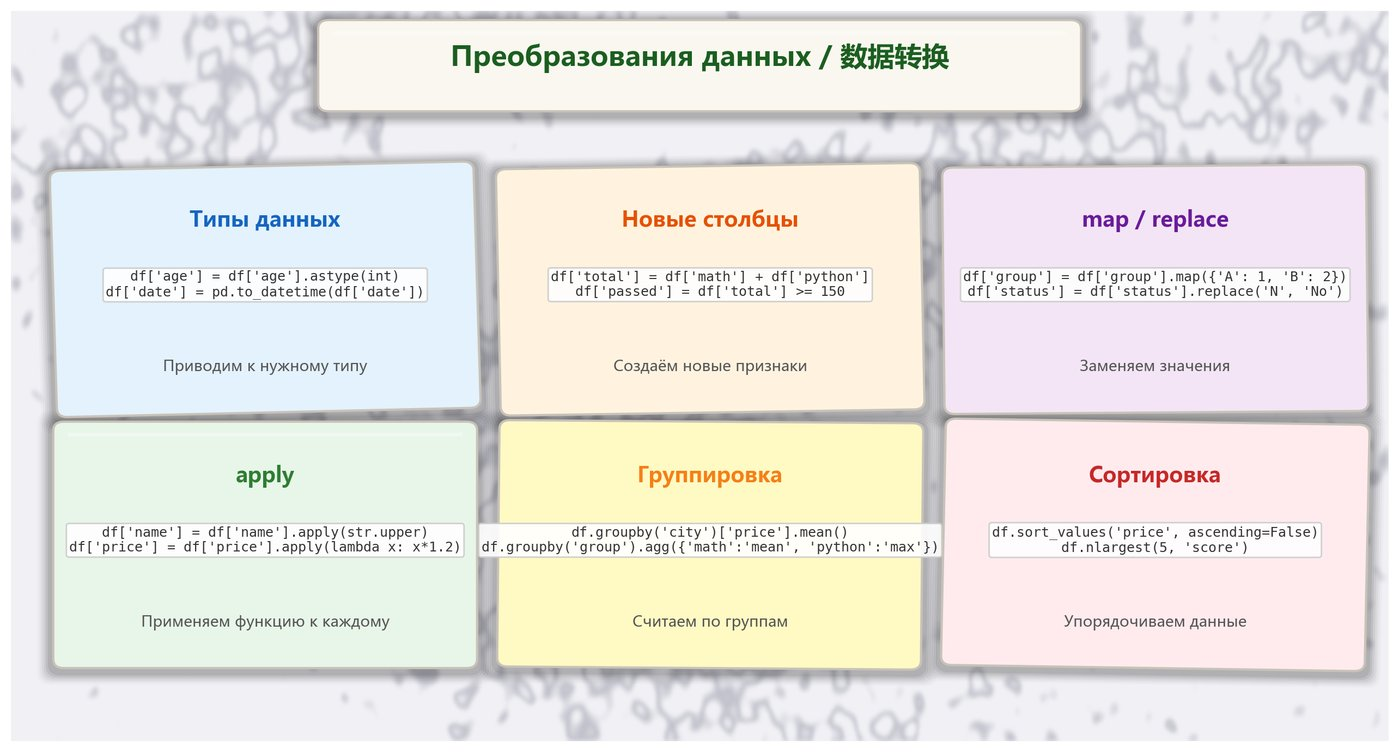
</div>

In [11]:
# 1. map — замена значений по словарю
df_clean['group_num'] = df_clean['group'].map({'A': 1, 'B': 2, 'C': 3})
print('После map:')
display(df_clean[['name', 'group', 'group_num']])

После map:


,name,group,group_num
0,Li,A,1
1,Wang,A,1
2,Zhang,B,2
3,Liu,B,2
4,Chen,A,1
5,Zhao,B,2
7,Zhou,B,2
8,Wu,A,1


In [12]:
# 2. apply — применяем функцию к каждому значению
df_clean['name_upper'] = df_clean['name'].apply(str.upper)
df_clean['score_rounded'] = df_clean['score'].apply(lambda x: round(x))
print('После apply:')
display(df_clean[['name', 'name_upper', 'score', 'score_rounded']])

После apply:


,name,name_upper,score,score_rounded
0,Li,LI,81.0,81
1,Wang,WANG,81.5,82
2,Zhang,ZHANG,85.0,85
3,Liu,LIU,77.0,77
4,Chen,CHEN,68.0,68
5,Zhao,ZHAO,88.0,88
7,Zhou,ZHOU,78.0,78
8,Wu,WU,86.0,86


In [13]:
# 3. Новые столбцы — вычисляемые признаки
df_clean['average'] = (df_clean['math'] + df_clean['python']) / 2
df_clean['passed'] = df_clean['average'] >= 75
df_clean['year'] = df_clean['date'].dt.year
df_clean['month'] = df_clean['date'].dt.month

print('С новыми признаками:')
display(df_clean[['name', 'math', 'python', 'average', 'passed', 'year', 'month']])

С новыми признаками:


,name,math,python,average,passed,year,month
0,Li,78.000000,85.0,81.500000,True,2025,9
1,Wang,92.000000,70.0,81.000000,True,2025,9
2,Zhang,84.833333,90.0,87.416667,True,2025,9
3,Liu,88.000000,80.0,84.000000,True,2025,9
4,Chen,71.000000,66.0,68.500000,False,2025,9
5,Zhao,95.000000,80.0,87.500000,True,2025,9
7,Zhou,84.833333,75.0,79.916667,True,2025,9
8,Wu,85.000000,88.0,86.500000,True,2025,9


In [14]:
# 4. replace — замена конкретных значений
df_clean['group'] = df_clean['group'].replace('C', 'B')  # группы C не существует
print('После replace:')
display(df_clean[['name', 'group']])

После replace:


,name,group
0,Li,A
1,Wang,A
2,Zhang,B
3,Liu,B
4,Chen,A
5,Zhao,B
7,Zhou,B
8,Wu,A


---
# 📊 Шаг 7. Группировка и агрегация

<div style='text-align: center; margin: 20px;'>
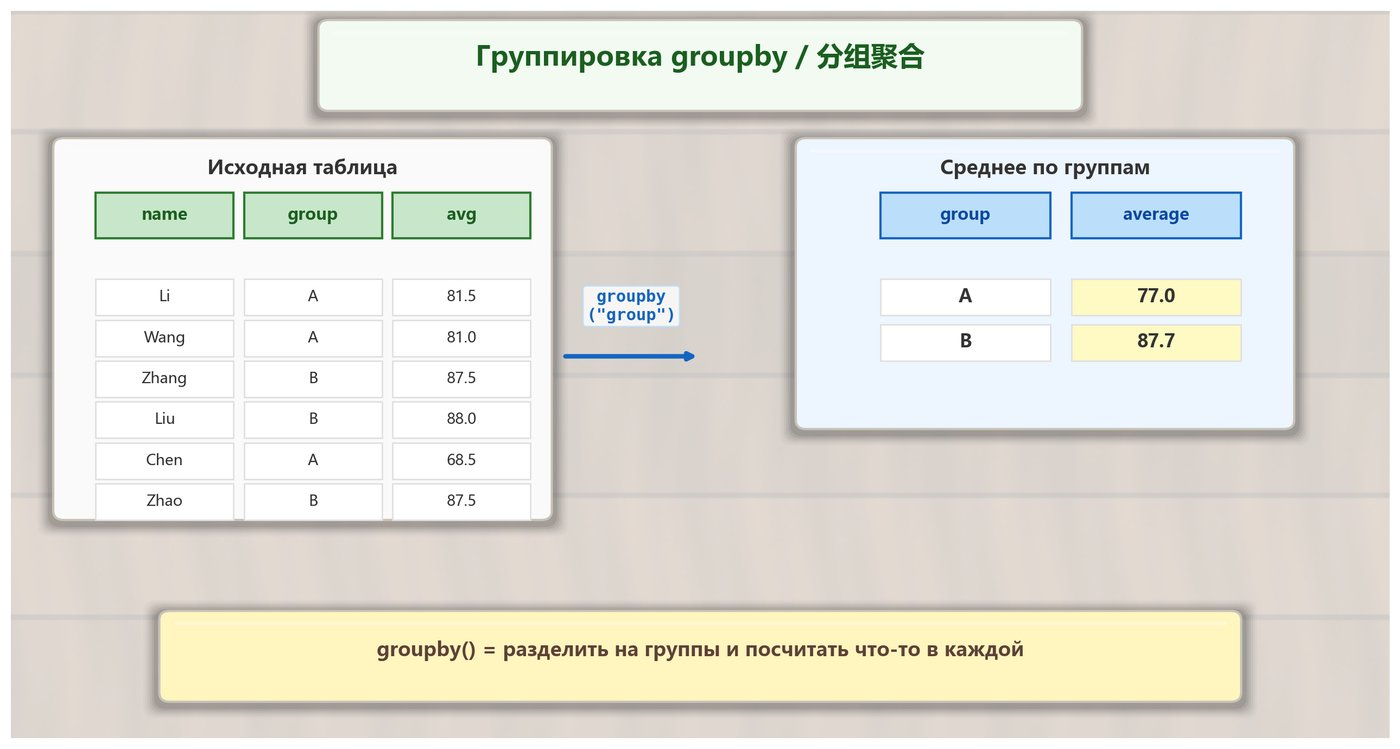
</div>

In [15]:
# Средний балл по группам
group_avg = df_clean.groupby('group')['average'].mean()
print('Средний балл по группам:')
print(group_avg)
print()

# Несколько агрегаций сразу
group_stats = df_clean.groupby('group').agg({
    'math': ['mean', 'min', 'max'],
    'python': ['mean', 'std'],
    'name': 'count'
})
print('Подробная статистика по группам:')
display(group_stats)

Средний балл по группам:
group
A    79.375000
B    84.708333
Name: average, dtype: float64

Подробная статистика по группам:


math                  python             name
            mean        min   max   mean        std count
group                                                    
A      81.500000  71.000000  92.0  77.25  10.874282     4
B      88.166667  84.833333  95.0  81.25   6.291529     4

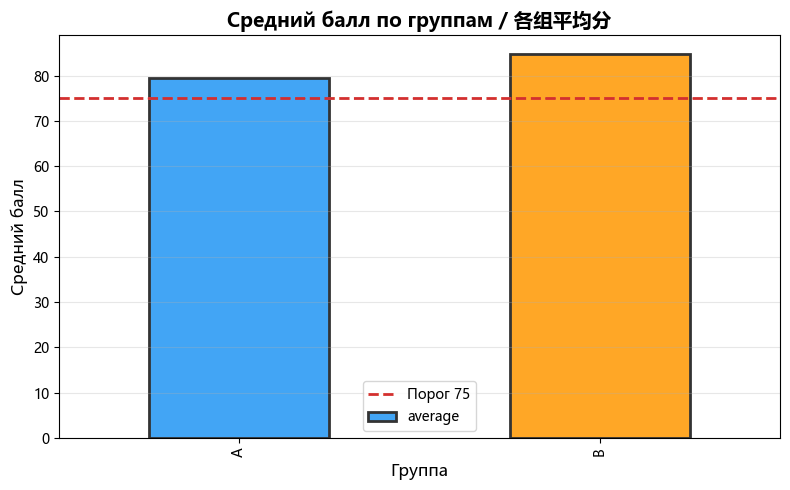

In [16]:
# Визуализация
fig, ax = plt.subplots(figsize=(8, 5))
group_avg.plot(kind='bar', color=['#42A5F5', '#FFA726'], edgecolor='#333', linewidth=2, ax=ax)
ax.set_title('Средний балл по группам / 各组平均分', fontsize=14, fontweight='bold')
ax.set_ylabel('Средний балл', fontsize=12)
ax.set_xlabel('Группа', fontsize=12)
ax.axhline(y=75, color='#D32F2F', linestyle='--', linewidth=2, label='Порог 75')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

---
# 💾 Шаг 8. Сохраняем чистые данные

In [17]:
# Сохраняем в CSV
df_clean.to_csv('students_clean.csv', index=False, encoding='utf-8-sig')
print('✅ Чистые данные сохранены в students_clean.csv')
print()

# Итоговая сводка
print('=== ИТОГОВАЯ СВОДКА ===')
print(f'Строк: {df_clean.shape[0]}')
print(f'Столбцов: {df_clean.shape[1]}')
print(f'Пропусков: {df_clean.isna().sum().sum()}')
print(f'Дубликатов: {df_clean.duplicated().sum()}')
print(f'Средний возраст: {df_clean["age"].mean():.1f}')
print(f'Средний балл: {df_clean["average"].mean():.1f}')

✅ Чистые данные сохранены в students_clean.csv

=== ИТОГОВАЯ СВОДКА ===
Строк: 8
Столбцов: 14
Пропусков: 0
Дубликатов: 0
Средний возраст: 20.6
Средний балл: 82.0


---
# 🎯 САМОСТОЯТЕЛЬНЫЕ ЗАДАНИЯ (10 минут)

Выполните три задания ниже. Каждое — в отдельной ячейке.

## Задание 1. Фильтрация

Выведите студентов, у которых:
- оценка по математике (`math`) **больше 80**, И
- средний балл (`average`) **не меньше 75**

In [18]:
# Ваш код здесь


## Задание 2. Новый признак

Добавьте столбец `grade`:
- если `average >= 85` → `'A'`
- если `average >= 75` → `'B'`
- иначе → `'C'`

**Подсказка:** используйте `pd.cut()` или `apply()` с функцией.

In [19]:
# Ваш код здесь


## Задание 3. Анализ

Посчитайте:
- Сколько студентов в каждой группе?
- Какой средний балл в каждой группе?
- Какой студент с самым высоким баллом в группе B?

In [20]:
# Ваш код здесь


---
## ✅ Чек-лист завершения практики

- [ ] Запустил ячейку с настройкой шрифтов
- [ ] Создал «грязную» таблицу
- [ ] Нашёл пропуски, дубликаты, выбросы
- [ ] Удалил дубликаты
- [ ] Обработал выбросы (удалил или ограничил)
- [ ] Заполнил пропуски (средним или медианой)
- [ ] Преобразовал типы данных
- [ ] Создал новые признаки
- [ ] Сгруппировал данные и посчитал статистику
- [ ] Построил диаграмму
- [ ] Сохранил чистые данные в CSV
- [ ] Выполнил 3 самостоятельных задания
- [ ] Сохранил тетрадь (Ctrl+S)

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #388E3C; margin: 20px 0;'>
<b>🏆 Отлично!</b> Вы прошли полный пайплайн очистки данных — это основа всех следующих практик и реальных проектов.
</div>

---
## 🆘 Типичные ошибки

| Ошибка | Причина | Решение |
|--------|---------|--------|
| `KeyError: 'math'` | Опечатка в имени столбца | Проверьте точное написание |
| `ValueError: could not convert string to float` | В столбце есть строки | Используйте `pd.to_numeric(..., errors='coerce')` |
| `SettingWithCopyWarning` | Работаете с копией | Используйте `.copy()` при создании новой таблицы |
| Квадраты вместо иероглифов | Не настроены шрифты | Выполните первую ячейку с `plt.rcParams` |
| `AttributeError: 'DataFrame' object has no attribute 'mean'` | Пытаетесь посчитать среднее по всей таблице | Укажите столбец: `df['math'].mean()` |
| График не показывается | Забыли `plt.show()` | Добавьте эту команду |
| `PermissionError` при сохранении CSV | Файл открыт в Excel | Закройте Excel |

---
## 📚 Ключевые термины практики

| Русский | 中文 | Что означает |
|---------|------|---------------|
| Пропуск | 缺失值 | NaN, отсутствующее значение |
| Выброс | 异常值 | Значение, сильно отличающееся от остальных |
| Дубликат | 重复值 | Повторяющаяся строка |
| Очистка данных | 数据清洗 | Удаление ошибок и приведение к нужному виду |
| Преобразование типа | 类型转换 | Изменение типа данных (строка → число) |
| Группировка | 分组 | Разделение данных на группы и подсчёт |
| Агрегация | 聚合 | Подсчёт статистики (среднее, сумма, максимум) |
| Пайплайн | 流程 | Последовательность шагов обработки |
| IQR | 四分位距 | Межквартильный размах (Q3 − Q1) |
| Медиана | 中位数 | Центральное значение в отсортированном ряду |

---
## 🏠 Домашнее задание

### Задание 1 (10 минут)
Создайте свою «грязную» таблицу из 10 строк и 5 столбцов с:
- 2 пропусками
- 1 выбросом
- 1 дубликатом
- 1 столбцом в неправильном типе

Очистите её и сохраните в CSV.

### Задание 2 (5 минут)
Посчитайте для своей таблицы:
- Среднее, медиану, стандартное отклонение по числовым столбцам
- Количество пропусков до и после очистки

### Задание 3 (по желанию, 10 минут)
Загрузите любой CSV-файл (например, из интернета или из Excel) и выполните полный пайплайн очистки.

<div style='background-color: #E3F2FD; padding: 15px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>💡 Совет:</b> Сохраните эту тетрадь — она станет шаблоном для всех будущих проектов. Пайплайн очистки универсален!
</div>

---
## <center>🎉 Практика завершена!</center>

### 📅 Следующее занятие

**Лекция 3:** Основы машинного обучения (классификация, регрессия, кластеризация)

**Практика 3:** Классификация ирисов — первый настоящий проект машинного обучения!

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата сдачи: _______________</i></center>
<center><i>Оценка: _____ / 100</i></center>